# 06. Risk-adaptive alert capacity

In this exploratory systems experiment on Binance spot BTCUSDT one-minute data, I ask whether a causal, risk-adaptive token-bucket refill improves crash detection before the 1% onset under the same hard ceiling of 240 alerts per year, without changing the V+F predictor. I fit the model on 2021 and calibrate thresholds on 2022 only. My historical diagnostic period is 2023-01-01 to 2026-04-30, which I have already inspected repeatedly. I compare four policies: the `first_eligible` and `absolute_high_score` calendar policies of notebook 05, a constant-rate token bucket and a risk-adaptive token bucket.

- I read the spot cache in `MyDrive/btc_lead_cost_results_77months_spot/`, which notebook 01 builds from the spot archive, and the reference values that notebook 05 saves in `spot_reference.json`.
- I write the results to `FINAL_risk_adaptive_alert_capacity_v1/`, including the 2022 constant- and risk-bucket thresholds in `spot_frozen_thresholds.json`, which notebook 07 reads.


## Design

I ask whether a causal risk-adaptive replenishment policy can improve pre-1%-onset crash detection under the same hard annual 240-alert ceiling, without changing the 2021-trained V+F predictor.

I froze the design in advance; the analysis is exploratory, not a new preregistered test. I fit the model on 2021 and use only 2022 data to calibrate thresholds and budget parameters. The historical diagnostic period, 2023-01-01 to 2026-04-30, is one I have already inspected repeatedly. The single primary outcome is an emitted alert 30–240 minutes before a fixed price-only 4% crash breach and strictly before the event's first 1% drawdown onset. The calendar budget cap is 20 per month and the annual cap is 240. The cooldown is 240 minutes.

I compare four policies: the notebook 05 `first_eligible` calendar, the notebook 05 `absolute_high_score` calendar, a constant-rate token bucket and a risk-adaptive token bucket. Both token buckets have a fixed 20-token burst capacity and a hard annual 240-alert ceiling. For the adaptive bucket, I make the refill proportional to realized BTC volatility over only the preceding seven completed UTC days, divided by the 2021 median and clipped to [0.5, 2.0]. The daily multiplier uses no look-ahead and no event labels. I introduce no new feature and no new crash model.

Equal budgets are caps; they do not guarantee equal realized alerts. The risk-adaptive token bucket can spend its allocation too early and may perform worse. I select no winner retrospectively. Notebook 07 evaluates May–September 2026.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display
import matplotlib.pyplot as plt

try:
    import pyarrow
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable,'-m','pip','-q','install','pyarrow'])
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local environment: set BASE to a folder with the same cache structure.')

BASE = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
# --- SPOT guard: this notebook may only read the spot cache built and fingerprint-verified by notebook 1 ---
import json as _json
_src_file = BASE/'cache'/'DATA_SOURCE.json'
if not _src_file.is_file() or _json.loads(_src_file.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Not a spot cache: {_src_file} is missing or venue!=spot. Run notebook 1 (1_..._SPOT) to completion first.')
print('SPOT cache verified:', _json.loads(_src_file.read_text())['market'])

SIGNALS = BASE / 'cache' / 'btc_signals_1m.parquet'
PRICE = BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet'
CATALOG = BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv'
OUT = BASE / 'FINAL_risk_adaptive_alert_capacity_v1'
OUT.mkdir(parents=True,exist_ok=True)
REF_PATH = BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
if not REF_PATH.is_file():
    raise FileNotFoundError(f'Run notebook 5 (Causal alert selection) first: {REF_PATH}')
REF = json.loads(REF_PATH.read_text())
assert REF.get('venue')=='spot'
for p in [SIGNALS,PRICE,CATALOG]:
    if not p.exists(): raise FileNotFoundError(str(p))
B=240; MONTH_CAP=20; COOLDOWN_MIN=240; LEAD_MIN=30; LEAD_MAX=240
BURST=20; RISK_MIN=0.5; RISK_MAX=2.0; TRAILING_DAYS=7
NS=60*10**9
print('Output:',OUT)

# Freeze and hash the analysis specification before computing historical evaluation results.
spec={
 'research_status':'retrospective exploratory; 2023-Apr2026 repeatedly inspected',
 'model_training_year':'2021', 'threshold_calibration_year':'2022',
 'historical_evaluation':'2023-01-01 through 2026-04-30',
 'model':'fixed V+F logistic from prior alert-selection notebook',
 'events':'fixed 4pct / 24h-refractory independent price-only catalog, pre1pct primary',
 'B':B,'calendar_month_cap':MONTH_CAP,'cooldown_minutes':COOLDOWN_MIN,
 'risk_stat':'1m squared log-return, past seven complete UTC days; 2021 reference median',
 'risk_weight_clipping':[RISK_MIN,RISK_MAX], 'risk_refill_rate_per_min':B/(365.2425*1440),
 'token_burst':BURST, 'annual_hard_cap':B,
 'risk_multiplier_selection':'pre-specified, no historical test labels',
 'bucket_threshold_selection':'2022 alert count only; strictest threshold on ties',
 'primary_endpoint':'alert 30-240m before 4pct breach and before onset_1pct',
 'no_new_prospective_test':True,
 'cannot_claim':'forecast accuracy improvement or economically optimal B without independent validation'
}
raw=(json.dumps(spec,indent=2,ensure_ascii=False)+'\n').encode('utf-8')
(OUT/'final_adaptive_study_spec.json').write_bytes(raw)
(OUT/'final_adaptive_study_spec.sha256').write_text(
    hashlib.sha256(raw).hexdigest()+'  final_adaptive_study_spec.json\n')


Mounted at /content/drive
SPOT cache verified: Binance spot BTCUSDT 1m klines
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/FINAL_risk_adaptive_alert_capacity_v1


97

## 1. Reproduce the V+F score and the independent crash catalog
Here I use the model and calibration grid of notebook 05 (causal alert selection) and reproduce exactly the spot baseline that notebook 05 saves in `spot_reference.json`; without that reproduction, any apparent improvement would be uninterpretable.

In [2]:
sig=pd.read_parquet(SIGNALS,columns=['z_vol','tsr','z_hs','price_lowvol']).sort_index()
px=pd.read_parquet(PRICE,columns=['close','volume']).sort_index()
assert sig.index.equals(px.index), 'Caches must have identical 1-minute indexes'
idx=pd.DatetimeIndex(sig.index)
assert idx.tz is not None
idx=idx.tz_convert('UTC')
assert idx.is_monotonic_increasing and not idx.has_duplicates
assert (np.diff(idx.asi8)==NS).all(), 'Input must be regular 1-min UTC data'
T=idx.asi8
v=sig.z_vol.to_numpy(float);f=sig.tsr.to_numpy(float); h=sig.z_hs.to_numpy(float)
close=px.close.to_numpy(float);volume=px.volume.to_numpy(float)
valid=(np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
       np.isfinite(v)&np.isfinite(f)&np.isfinite(h)&(f>=0)&(f<=1))
E=pd.read_csv(CATALOG)
for col in ['breach_utc','onset_1pct_utc','confirmed_utc']:
    E[col]=pd.to_datetime(E[col],utc=True)
E=E.sort_values('breach_utc').reset_index(drop=True)
assert E.event_id.is_unique
breach_ns=E.breach_utc.astype('int64').to_numpy()
pos=np.searchsorted(breach_ns,T+LEAD_MIN*NS,'left')
y=np.zeros(len(T),np.int8)
ok=pos<len(breach_ns)
y[ok]=(breach_ns[pos[ok]]<=T[ok]+LEAD_MAX*NS).astype('int8')
train=valid&(T>=pd.Timestamp('2021-01-01',tz='UTC').value)&(T<pd.Timestamp('2022-01-01',tz='UTC').value-(LEAD_MAX+5)*NS)
cal=valid&(T>=pd.Timestamp('2022-01-01',tz='UTC').value)&(T<pd.Timestamp('2023-01-01',tz='UTC').value)
ev_mask=valid&(T>=pd.Timestamp('2023-01-01',tz='UTC').value)&(T<pd.Timestamp('2026-05-01',tz='UTC').value)
assert train.any() and cal.any() and ev_mask.any() and 0<y[train].sum()<train.sum()
X=np.column_stack((v,f))
clf=make_pipeline(StandardScaler(),LogisticRegression(C=0.2,class_weight='balanced',
    max_iter=400,solver='lbfgs',random_state=17))
clf.fit(X[train],y[train])
S=np.full(len(T),np.nan,float)
S[valid]=clf.predict_proba(X[valid])[:,1]
T_CAL=T[cal]; S_CAL=S[cal]; T_EVAL=T[ev_mask];S_EVAL=S[ev_mask]
EVENTS=E[(E.breach_utc>=pd.Timestamp('2023-01-01 04:00',tz='UTC'))&
         (E.breach_utc<pd.Timestamp('2026-05-01',tz='UTC'))].reset_index(drop=True)
assert len(EVENTS)==REF['n_primary_events'], f"Event catalog differs from notebook 5 ({len(EVENTS)} vs {REF['n_primary_events']})"
print('Training minutes:',int(train.sum()),'Calibration:',len(T_CAL),'Evaluation:',len(T_EVAL), 'Events:',len(EVENTS))

Training minutes: 524087 Calibration: 525600 Evaluation: 1750857 Events: 83


## 2. Compute the causal daily volatility multiplier
On UTC day *d*, the policy uses completed one-minute returns only through the end of day *d−1*. A 2021 reference median fixes the units, and I use no 2023+ outcomes to build the multiplier.

In [3]:
logclose=np.log(close)
ret=np.r_[np.nan,np.diff(logclose)]
usable=(np.isfinite(ret)&np.isfinite(close)&(close>0)&(volume>0)&
        np.r_[False,(volume[:-1]>0)&np.isfinite(close[:-1])&(close[:-1]>0)])
ret2=pd.Series(np.where(usable,ret*ret,np.nan),index=idx)
# Mean squared 1m return per *completed* UTC day; missing/minimal days excluded.
DAYS=pd.DataFrame({'ms':ret2.resample('D').mean(),'n':ret2.resample('D').count()})
DAYS.loc[DAYS.n<1000,'ms']=np.nan
# Shift by one day before the rolling 7-day mean; calendar-day causal.
DAYS['trailing_7d_rv']=np.sqrt(DAYS.ms.shift(1).rolling(TRAILING_DAYS,min_periods=TRAILING_DAYS).mean())
ref=DAYS.loc['2021-01-01':'2021-12-31','trailing_7d_rv'].median()
assert np.isfinite(ref) and ref>0
DAYS['risk_weight']=np.clip(DAYS.trailing_7d_rv/ref,RISK_MIN,RISK_MAX).fillna(1.0)
risk_full=DAYS.risk_weight.reindex(idx.floor('D')).to_numpy(float)
assert len(risk_full)==len(T) and np.isfinite(risk_full).all()
assert np.all((risk_full>=RISK_MIN)&(risk_full<=RISK_MAX))
# Per-calendar-minute cumulative token credit; no future weights are consulted by online scheduler.
# The coefficient is B tokens per year at neutral weight 1.0.
rate_per_min=B/(365.2425*1440)
credit_full=np.cumsum(rate_per_min*risk_full,dtype=np.float64)
C_CAL=credit_full[cal];C_EVAL=credit_full[ev_mask]
DAYS.to_csv(OUT/'causal_risk_weight_by_utc_day.csv')
print('2021 reference volatility:',ref)
print('Daily multiplier (2022):',DAYS.loc['2022','risk_weight'].describe().to_dict())

2021 reference volatility: 0.001085106141933696
Daily multiplier (2022): {'count': 365.0, 'mean': 0.7962905363053829, 'std': 0.2841228410487704, 'min': 0.5, '25%': 0.6092407752503082, '50%': 0.7382887761826187, '75%': 0.8710843927470747, 'max': 1.9033771010869498}


## 3. Online schedulers, event matching, and strict event-level comparisons
Both token buckets start each UTC year with 20 tokens, and unspent tokens never exceed the 20-token capacity. Neither bucket can borrow capacity from the future. I define the adaptive rate as a *candidate-time cumulative historical credit increment*, not as a multiplier applied to future elapsed time.

In [4]:
def emit_policy(t, scores, threshold, mode, *, credits=None, B=240, month_cap=20,
                burst=20, cooldown=240):
    t=np.asarray(t,np.int64);sc=np.asarray(scores,float)
    assert len(t)==len(sc) and (len(t)<2 or (np.diff(t)>0).all())
    if mode=='risk_bucket':
        assert credits is not None and len(credits)==len(t)
        credits=np.asarray(credits,float)
    assert mode in {'calendar','constant_bucket','risk_bucket'}
    cand=np.flatnonzero(np.isfinite(sc)&(sc>=threshold))
    emitted=[];annual=0;monthly=0;py=None;pm=None;prev=-10**25
    tokens=float(burst); last_t=None;last_credit=None
    for k in cand:
        tm=int(t[k]);stamp=pd.Timestamp(tm,tz='UTC')
        yr=int(stamp.year);mon=int(stamp.month)
        if yr!=py:
            py=yr;annual=0;tokens=float(burst);last_t=tm
            last_credit=None if credits is None else float(credits[k])
        if (yr,mon)!=pm:
            pm=(yr,mon);monthly=0
        if mode=='constant_bucket':
            if last_t is not None and tm>last_t:
                tokens=min(float(burst),tokens+(tm-last_t)/NS*B/(365.2425*1440))
            last_t=tm
        elif mode=='risk_bucket':
            if last_credit is not None:
                tokens=min(float(burst),tokens+max(0,float(credits[k])-last_credit))
            last_credit=float(credits[k])
        if annual>=B:continue
        if mode=='calendar' and monthly>=month_cap:continue
        if mode!='calendar' and tokens<1-1e-9:continue
        if tm-prev<cooldown*NS:continue
        emitted.append(tm);prev=tm;annual+=1;monthly+=1
        if mode!='calendar':tokens=max(0.0,tokens-1.0)
    return np.array(emitted,dtype=np.int64)

def match_events(events,alerts):
    a=np.sort(np.asarray(alerts,np.int64));claimed=set();rows=[]
    for event in events.itertuples(index=False):
        breach=int(event.breach_utc.value);onset=int(event.onset_1pct_utc.value)
        L=np.searchsorted(a,breach-LEAD_MAX*NS,'left')
        R=np.searchsorted(a,breach-LEAD_MIN*NS,'right')
        for j in range(L,R):
            if j in claimed: continue
            claimed.add(j)
            rows.append({'event_id':int(event.event_id),'alarm_utc':pd.Timestamp(int(a[j]),tz='UTC'),
                         'breach_utc':event.breach_utc,'lead_min':(breach-int(a[j]))/NS,
                         'pre1pct':bool(int(a[j])<onset)})
            break
    return pd.DataFrame(rows,columns=['event_id','alarm_utc','breach_utc','lead_min','pre1pct'])

def summary(events,alerts):
    hit=match_events(events,alerts)
    return {'alarms':len(alerts),'events':len(events),'caught':len(hit),
            'pre_onset':int(hit.pre1pct.sum()),'false_alarms':len(alerts)-len(hit),
            'event_recall':len(hit)/len(events),'pre_onset_recall':int(hit.pre1pct.sum())/len(events),
            'alarm_precision':len(hit)/len(alerts) if len(alerts)>0 else np.nan}

# Tests: monotonic and chronological, annual cap, cooldown, risk credit rate.
toy=pd.date_range('2022-01-01',periods=60,freq='h',tz='UTC').asi8
sc=np.ones(len(toy))
for m in ['calendar','constant_bucket','risk_bucket']:
    credits=np.arange(len(toy),dtype=float)*5 if m=='risk_bucket' else None
    a=emit_policy(toy,sc,.5,m,credits=credits,B=12,month_cap=1,burst=2)
    assert len(a)<=12 and (len(a)<=1 or np.all(np.diff(a)>=240*NS))
assert len(emit_policy(toy,sc,.5,'calendar',B=12,month_cap=1))==1
assert len(emit_policy(toy,np.zeros(len(toy)),.5,'risk_bucket',credits=np.arange(len(toy))))==0
print('Online scheduling and matching helper tests passed')

Online scheduling and matching helper tests passed


## 4. Reproduce existing 2022 model calibration and frozen historical baseline
I use no test-period labels for *any* threshold. For the calendar and high-score policies I keep the frozen threshold choices of notebook 05.

In [5]:
QUANTILES=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
TH_GRID=np.unique(np.r_[np.nextafter(S_CAL.min(),-np.inf),np.quantile(S_CAL,QUANTILES),
                        np.nextafter(S_CAL.max(),np.inf)])
# Frozen thresholds of notebook 5 (2022 calibration, not re-optimized here):
BASELINE_TH=float(REF['TH_CAL'])       # spot 2022 calibration from notebook 5
HIGH_SCORE_TH=float(REF['TH_HIGH'])    # spot 2022 calibration from notebook 5

base_alert=emit_policy(T_EVAL,S_EVAL,BASELINE_TH,'calendar')
high_alert=emit_policy(T_EVAL,S_EVAL,HIGH_SCORE_TH,'calendar')
BASE_STATS=summary(EVENTS,base_alert)
HIGH_STATS=summary(EVENTS,high_alert)
print('Published first-eligible:',BASE_STATS)
print('Published high-score:',HIGH_STATS)
if [BASE_STATS['alarms'],BASE_STATS['caught'],BASE_STATS['pre_onset']]!=REF['first_eligible']:
    raise RuntimeError(f"FAIL: notebook-5 spot baseline {REF['first_eligible']} not reproduced. Stop: inspect cache/model/event matching.")
if [HIGH_STATS['alarms'],HIGH_STATS['caught'],HIGH_STATS['pre_onset']]!=REF['absolute_high_score']:
    raise RuntimeError(f"FAIL: notebook-5 spot high-score benchmark {REF['absolute_high_score']} not reproduced. Stop.")
print('Spot reference reproduced:',REF['first_eligible'],REF['absolute_high_score'])

Published first-eligible: {'alarms': 800, 'events': 83, 'caught': 39, 'pre_onset': 22, 'false_alarms': 761, 'event_recall': 0.46987951807228917, 'pre_onset_recall': 0.26506024096385544, 'alarm_precision': 0.04875}
Published high-score: {'alarms': 800, 'events': 83, 'caught': 41, 'pre_onset': 19, 'false_alarms': 759, 'event_recall': 0.4939759036144578, 'pre_onset_recall': 0.2289156626506024, 'alarm_precision': 0.05125}
Spot reference reproduced: [800, 39, 22] [800, 41, 19]


## 5. Choose only the two token-bucket thresholds from 2022
For each token bucket I choose the threshold that minimizes `abs(2022 alarms-240)`, breaking ties toward the stricter threshold. I also run a fixed-score arm to isolate scheduler effects. I do not tune the risk multiplier, the seven-day window, the clipping or the token burst on historical test-period outcomes.

In [6]:
cal_rows=[]
for mode in ['constant_bucket','risk_bucket']:
    for th in TH_GRID:
        alerts=emit_policy(T_CAL,S_CAL,float(th),mode,credits=C_CAL if mode=='risk_bucket' else None)
        cal_rows.append({'mode':mode,'threshold':float(th),'calibration_alarms':len(alerts),
                         'distance_to_240':abs(len(alerts)-B)})
cal_grid=pd.DataFrame(cal_rows)
choices={}
for mode,g in cal_grid.groupby('mode',sort=False):
    row=g.sort_values(['distance_to_240','threshold'],ascending=[True,False]).iloc[0]
    choices[mode]=float(row.threshold)
cal_grid.to_csv(OUT/'threshold_search_2022.csv',index=False)
print('Frozen 2022 choices:',choices)
FROZEN_THRESHOLDS={'venue':'spot','TH_CAL':BASELINE_TH,'TH_HIGH':HIGH_SCORE_TH,
    'TH_BUCKET':float(choices['constant_bucket']),'TH_RISK_BUCKET':float(choices['risk_bucket']),
    'note':'TH_CAL/TH_HIGH from notebook 5; buckets from 2022 alert counts here. Read by notebook 7.'}
(OUT/'spot_frozen_thresholds.json').write_text(json.dumps(FROZEN_THRESHOLDS,indent=2))
print('Saved for notebook 7:',FROZEN_THRESHOLDS)
print(cal_grid.loc[cal_grid.apply(lambda r:np.isclose(r.threshold,choices[r['mode']]),axis=1)].to_string(index=False))

Frozen 2022 choices: {'constant_bucket': 0.7166067355142407, 'risk_bucket': 0.6698990591069133}
Saved for notebook 7: {'venue': 'spot', 'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407, 'TH_RISK_BUCKET': 0.6698990591069133, 'note': 'TH_CAL/TH_HIGH from notebook 5; buckets from 2022 alert counts here. Read by notebook 7.'}
           mode  threshold  calibration_alarms  distance_to_240
constant_bucket   0.716607                 240                0
    risk_bucket   0.669899                 210               30


## 6. Historical evaluation (retrospective and exploratory)
I evaluate the notebook 05 calendar and high-score policies, the constant and risk buckets at a fixed threshold, and the separately recalibrated constant and risk buckets. I report all policies and do not select the historical best.

In [7]:
plans=[('calendar_published','calendar',BASELINE_TH),
       ('high_score_published','calendar',HIGH_SCORE_TH),
       ('constant_bucket_fixedscore','constant_bucket',BASELINE_TH),
       ('risk_bucket_fixedscore','risk_bucket',BASELINE_TH),
       ('constant_bucket_recalibrated','constant_bucket',choices['constant_bucket']),
       ('risk_bucket_recalibrated','risk_bucket',choices['risk_bucket'])]
all_alerts={}; all_matches={};rows=[]
for name,mode,th in plans:
    alert=emit_policy(T_EVAL,S_EVAL,th,mode,credits=C_EVAL if mode=='risk_bucket' else None)
    hit=match_events(EVENTS,alert)
    stats=summary(EVENTS,alert)
    rows.append(dict(policy=name,mode=mode,threshold=th,**stats))
    all_alerts[name]=alert;all_matches[name]=hit
    pd.DataFrame({'alarm_utc':pd.to_datetime(alert,utc=True)}).to_csv(OUT/f'alarms_{name}.csv',index=False)
    hit.to_csv(OUT/f'matched_{name}.csv',index=False)
results=pd.DataFrame(rows)
results.to_csv(OUT/'risk_adaptive_policy_comparison.csv',index=False)
display(results.round(5))

,policy,mode,threshold,alarms,events,caught,pre_onset,false_alarms,event_recall,pre_onset_recall,alarm_precision
0,calendar_published,calendar,0.66990,800,83,39,22,761,0.46988,0.26506,0.04875
1,high_score_published,calendar,0.68648,800,83,41,19,759,0.49398,0.22892,0.05125
2,constant_bucket_fixedscore,constant_bucket,0.66990,816,83,28,10,788,0.33735,0.12048,0.03431
3,risk_bucket_fixedscore,risk_bucket,0.66990,565,83,20,7,545,0.24096,0.08434,0.03540
4,constant_bucket_recalibrated,constant_bucket,0.71661,795,83,48,18,747,0.57831,0.21687,0.06038
5,risk_bucket_recalibrated,risk_bucket,0.66990,565,83,20,7,545,0.24096,0.08434,0.03540


## 7. Month-by-month capacity exhaustion, and event-level loss decomposition
A crash that occurs *after* quota exhaustion is not the same as an event that had zero eligible-capacity minutes throughout its 30–240-minute warning window. Likewise, I do not take an un-emitted score crossing as proof that a different allocation would have triggered an alert.

In [8]:
mon_rows=[];decomp_rows=[];event_rows=[]
for name,mode,th in plans:
    a=all_alerts[name]
    adt=pd.to_datetime(a,utc=True)
    counts=pd.Series(1,index=adt).resample('MS').sum().reindex(pd.date_range('2023-01-01','2026-04-01',freq='MS',tz='UTC'),fill_value=0)
    for date,ct in counts.items():
        sub=adt[(adt.year==date.year)&(adt.month==date.month)]
        mon_rows.append({'policy':name,'month':str(date)[:7],'alerts':int(ct),
             'final_alert_utc':str(sub.max()) if len(sub) else None,
             'last_alert_day':int(sub.max().day) if len(sub) else np.nan,
             'calendar_cap_hit':bool(mode=='calendar' and ct>=MONTH_CAP)})
    matched=set(all_matches[name].event_id.astype(int))
    # Every event window has 211 calendar minutes by definition. Capacity is checked at each one.
    # For risk tokens, calculate *exact* remaining capacity by replaying scheduler on the raw
    # scored timeline is a separate counterfactual; here only causal hard annual quota is tested.
    for ev in EVENTS.itertuples(index=False):
        b=int(ev.breach_utc.value)
        event_rows.append({'policy':name,'event_id':int(ev.event_id),'breach_utc':ev.breach_utc,
                           'caught':int(ev.event_id) in matched})
months=pd.DataFrame(mon_rows);months.to_csv(OUT/'monthly_alert_exhaustion.csv',index=False)
events_df=pd.DataFrame(event_rows);events_df.to_csv(OUT/'event_level_policy_hits.csv',index=False)
# Capacity audit only for published calendar model (hard month+annual cap), using its exact emitted timestamps.
calendar_by_mon={m:np.sort(np.asarray(v,dtype=np.int64)) for m,v in
        pd.DataFrame({'t':base_alert,'m':pd.to_datetime(base_alert,utc=True).to_period('M').astype(str)}).groupby('m')['t']}
records=[]
for ev in EVENTS.itertuples(index=False):
    b=int(ev.breach_utc.value)
    candidate_idx=np.flatnonzero((T_EVAL>=b-LEAD_MAX*NS)&(T_EVAL<=b-LEAD_MIN*NS)&(S_EVAL>=BASELINE_TH))
    # For each eligible clock minute, use actual number of already-issued alerts in that month/year.
    has_calendar_room=False
    for ti in range(b-LEAD_MAX*NS,b-LEAD_MIN*NS+1,NS):
        dt=pd.Timestamp(ti,tz='UTC');month=str(dt.to_period('M'))
        hist=calendar_by_mon.get(month,np.empty(0,np.int64))
        nm=int(np.searchsorted(hist,ti,side='right'))
        if nm<MONTH_CAP:
            has_calendar_room=True;break
    eligible_candidates=len(candidate_idx)
    hit=int(ev.event_id) in set(all_matches['calendar_published'].event_id)
    category='caught' if hit else ('missed_no_calendar_room' if not has_calendar_room else 'missed_some_calendar_room')
    records.append({'event_id':int(ev.event_id),'breach_utc':ev.breach_utc,'caught':hit,
       'has_any_calendar_room_in_warning_window':has_calendar_room,
       'any_raw_candidate':eligible_candidates>0,'n_raw_candidate_minutes':eligible_candidates,
       'category':category})
audit=pd.DataFrame(records)
audit.to_csv(OUT/'baseline_capacity_event_decomposition.csv',index=False)
print('Calendar capacity decomposition:',audit.category.value_counts().to_dict())
print('Raw signal candidates in no-room missed events:',
    int(((audit.category=='missed_no_calendar_room')&audit.any_raw_candidate).sum()))
_dec=audit.category.value_counts().to_dict()
assert _dec.get('caught',0)==BASE_STATS['caught'], 'Capacity decomposition disagrees with the calendar baseline hit count'
assert sum(_dec.values())==len(EVENTS)
print('Spot capacity decomposition:',_dec,'| futures data: caught 35 / no room 38 / some room 11')

/tmp/ipykernel_4243/2847703346.py:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  pd.DataFrame({'t':base_alert,'m':pd.to_datetime(base_alert,utc=True).to_period('M').astype(str)}).groupby('m')['t']}
/tmp/ipykernel_4243/2847703346.py:32: UserWarning: Converting to Period representation will drop timezone information.
  dt=pd.Timestamp(ti,tz='UTC');month=str(dt.to_period('M'))


Calendar capacity decomposition: {'caught': 39, 'missed_no_calendar_room': 33, 'missed_some_calendar_room': 11}
Raw signal candidates in no-room missed events: 25
Spot capacity decomposition: {'caught': 39, 'missed_no_calendar_room': 33, 'missed_some_calendar_room': 11} | futures data: caught 35 / no room 38 / some room 11


## 8. Paired early-detection comparisons and budget accounting
I use the exact McNemar test as a descriptive paired diagnostic for the reused 2023 to April 2026 period, not as a new confirmatory p-value. Because a policy may emit fewer alerts, I report raw alert counts alongside paired hits.

In [9]:
ids=EVENTS.event_id.astype(int).to_numpy()
base_mat=all_matches['calendar_published']; base_early=set(base_mat.loc[base_mat.pre1pct,'event_id'].astype(int))
base_hit=set(base_mat.event_id.astype(int))
paired=[]
for name,_,_ in plans:
    if name=='calendar_published':continue
    mm=all_matches[name]
    eh=set(mm.loc[mm.pre1pct,'event_id'].astype(int));hh=set(mm.event_id.astype(int))
    aonly=len(base_early-eh);bonly=len(eh-base_early)
    aonly_h=len(base_hit-hh);bonly_h=len(hh-base_hit)
    paired.append(dict(policy=name,baseline_alerts=len(base_alert),policy_alerts=len(all_alerts[name]),
       baseline_pre1pct=len(base_early),policy_pre1pct=len(eh),
       baseline_only_early=aonly,policy_only_early=bonly,
       mcnemar_pre1pct_p=binomtest(min(aonly,bonly),aonly+bonly,.5).pvalue if aonly+bonly else 1.,
       baseline_caught=len(base_hit),policy_caught=len(hh),
       baseline_only_caught=aonly_h,policy_only_caught=bonly_h,
       mcnemar_caught_p=binomtest(min(aonly_h,bonly_h),aonly_h+bonly_h,.5).pvalue if aonly_h+bonly_h else 1.))
paired=pd.DataFrame(paired);paired.to_csv(OUT/'paired_risk_adaptive_comparison.csv',index=False)
display(paired.round(5))
years=[]
for name,_,_ in plans:
    a=all_alerts[name]
    for yr in range(2023,2027):
        ae=a[(pd.to_datetime(a,utc=True).year==yr)]
        ee=EVENTS[EVENTS.breach_utc.dt.year==yr]
        yrs=summary(ee,ae)
        years.append({'policy':name,'year':yr,**yrs})
yrs=pd.DataFrame(years);yrs.to_csv(OUT/'risk_adaptive_year_by_year.csv',index=False)
display(yrs[['policy','year','alarms','caught','pre_onset']])

,policy,baseline_alerts,policy_alerts,baseline_pre1pct,policy_pre1pct,baseline_only_early,policy_only_early,mcnemar_pre1pct_p,baseline_caught,policy_caught,baseline_only_caught,policy_only_caught,mcnemar_caught_p
0,high_score_published,800,800,22,19,5,2,0.45312,39,41,3,5,0.72656
1,constant_bucket_fixedscore,800,816,22,10,15,3,0.00754,39,28,21,10,0.07076
2,risk_bucket_fixedscore,800,565,22,7,17,2,0.00073,39,20,25,6,0.00088
3,constant_bucket_recalibrated,800,795,22,18,11,7,0.48068,39,48,10,19,0.13605
4,risk_bucket_recalibrated,800,565,22,7,17,2,0.00073,39,20,25,6,0.00088


,policy,year,alarms,caught,pre_onset
0,calendar_published,2023,240,7,3
1,calendar_published,2024,240,17,7
2,calendar_published,2025,240,12,9
3,calendar_published,2026,80,3,3
4,high_score_published,2023,240,6,2
5,high_score_published,2024,240,16,5
6,high_score_published,2025,240,16,9
7,high_score_published,2026,80,3,3
8,constant_bucket_fixedscore,2023,240,5,3
9,constant_bucket_fixedscore,2024,240,11,2


## 9. Visual diagnostics and study record
I base no model selection on any 2023+ outcome.

Frozen study SHA-256: 1703156f64803c870af65fcc7a0b1d12d1bdd6bef1e6b7b4d34d46f645416839


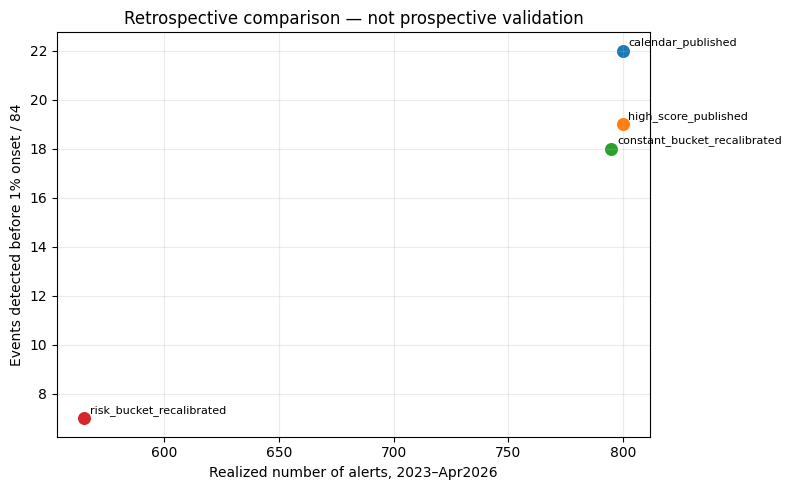

Saved to: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/FINAL_risk_adaptive_alert_capacity_v1
Earlier work viewed some prices from May 2026 onward, so this period is not a never-seen holdout.


In [10]:
# Ensure specification was not altered during this notebook run.
spec_bytes=(OUT/'final_adaptive_study_spec.json').read_bytes()
digest=hashlib.sha256(spec_bytes).hexdigest()
recorded=(OUT/'final_adaptive_study_spec.sha256').read_text().split()[0]
assert digest==recorded, 'Study specification changed during execution'
print('Frozen study SHA-256:',digest)
plt.figure(figsize=(8,5))
for name in ['calendar_published','high_score_published','constant_bucket_recalibrated','risk_bucket_recalibrated']:
    r=results.set_index('policy').loc[name]
    plt.scatter([r['alarms']],[r['pre_onset']],s=70)
    plt.annotate(name, (r['alarms'],r['pre_onset']),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.xlabel('Realized number of alerts, 2023–Apr2026')
plt.ylabel('Events detected before 1% onset / 83')
plt.title('Retrospective comparison — not prospective validation')
plt.grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT/'risk_adaptive_early_recall_vs_alerts.png',dpi=180)
plt.show()
print('Saved to:',OUT)
print('Earlier work viewed some prices from May 2026 onward, so this period is not a never-seen holdout.')